# We will create a class for Gradient Descent.
# We will create this class in two steps.
# 1) We will implement logic to find best value for `c (intercept)`
# 2)  We will implement logic to find best value for `c (intercept)` and `b(slope)` both.

In [59]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt

import numpy as np

np.set_printoptions(suppress=True, precision=4)
np.set_printoptions(suppress=True)

In [60]:
x, y = make_regression(
    n_samples = 100,
    n_features = 1,
    n_informative = 1,
    n_targets = 1,
    noise = 20,
    random_state = 1
)

print(x[0:5])
print()
print()

print(y[0:5])

[[-0.6118]
 [-0.2494]
 [ 0.4885]
 [ 0.762 ]
 [ 1.5198]]


[-55.5386 -10.662   22.7574 101.0961 144.3376]


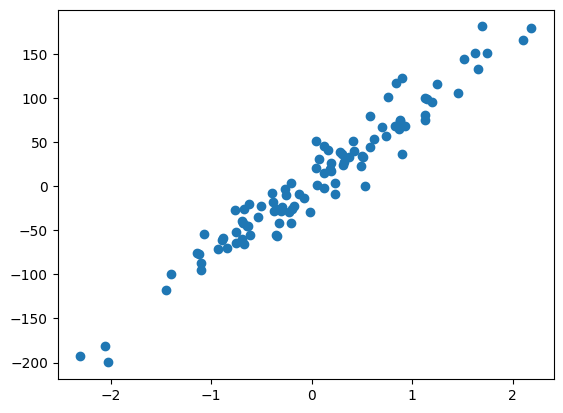

In [61]:
# plotting the data to know the distribution
plt.scatter(x, y)

# Get slope and intercept from sklearn.LinearRegressor so that we can substitute the value of slope and find best value for intercept

In [62]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(x, y)

m = lr_model.coef_[0]
c = lr_model.intercept_

print(f"Slope: {m}")
print(f"Intercept: {c}")

# We will fix the slope

Slope: 82.48449929280291
Intercept: 4.054028777621713


# Creating the class.

Note: Here we are keeping `slope(m)` as constant and only finding the best value for `intercept (c)`

In [63]:
class GDRegressor:
    def __init__(self, m, learning_rate, epochs):
        self.m = m
        self.c = -100    # Initializing the random value for c
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, x, y):

        x = x.ravel()
        y = y.ravel()
        
        # Calculate b using formula: Cnew = Cold -  (lr).(Slope of Cold)
        # Formula of Slope: slope = (-2)* np.sum(y.ravel() - (m)(x.ravel()) - c.ravel())

        for i in range(self.epochs):
            slope = (-2)* np.sum(y - (self.m)*(x) - self.c)
            self.c = (self.c) - (self.learning_rate)*(slope)

            print(f'''Slope: {slope}
Intercept(c): {self.c}
-----------------------------------''')

        print(self.c)

In [64]:
gd = GDRegressor(
    m = m,
    learning_rate = 0.1,    # High learning rate
    epochs = 10
)

gd.fit(x, y)

Slope: -20810.80575552434
Intercept(c): 1981.0805755524339
-----------------------------------
Slope: 395405.30935496243
Intercept(c): -37559.45035994381
-----------------------------------
Slope: -7512700.877744286
Intercept(c): 713710.6374144849
-----------------------------------
Slope: 142741316.67714143
Intercept(c): -13560421.030299658
-----------------------------------
Slope: -2712085016.8656864
Intercept(c): 257648080.656269
-----------------------------------
Slope: 51529615320.448044
Intercept(c): -4895313451.3885355
-----------------------------------
Slope: -979062691088.5127
Intercept(c): 93010955657.46274
-----------------------------------
Slope: 18602191130681.742
Intercept(c): -1767208157410.7117
-----------------------------------
Slope: -353441631482953.1
Intercept(c): 33576954990884.6
-----------------------------------
Slope: 6715390998176109.0
Intercept(c): -637962144826726.2
-----------------------------------
-637962144826726.2


Why are we getting such a weird value for intercept(c)?

This is because we set learning rate very high and beacuse of this, we are moving to and fro i.e left-right-left-right.
See the results of how slope is updated and changes in intercept(c)

To solve this, we will have to reduce the learning_rate and increase the epochs.

In [65]:
# Reduce learning rate and increase no_of_epochs

gd = GDRegressor(
    m = m,
    learning_rate = 0.01,    # From 0.1 to 0.01
    epochs = 10
)

gd.fit(x, y)

Slope: -20810.80575552434
Intercept(c): 108.10805755524339
-----------------------------------
Slope: 20810.805755524332
Intercept(c): -99.99999999999994
-----------------------------------
Slope: -20810.80575552433
Intercept(c): 108.10805755524333
-----------------------------------
Slope: 20810.805755524325
Intercept(c): -99.99999999999991
-----------------------------------
Slope: -20810.80575552432
Intercept(c): 108.1080575552433
-----------------------------------
Slope: 20810.805755524318
Intercept(c): -99.99999999999989
-----------------------------------
Slope: -20810.805755524318
Intercept(c): 108.1080575552433
-----------------------------------
Slope: 20810.805755524318
Intercept(c): -99.99999999999989
-----------------------------------
Slope: -20810.805755524318
Intercept(c): 108.1080575552433
-----------------------------------
Slope: 20810.805755524318
Intercept(c): -99.99999999999989
-----------------------------------
-99.99999999999989


In [66]:
# Let's reduce learning_rate further form 0.01 to 0.001 and epochs = 20

gd = GDRegressor(
    m = m,
    learning_rate = 0.001,
    epochs = 100
)

gd.fit(x, y)

Slope: -20810.80575552434
Intercept(c): -79.18919424447566
-----------------------------------
Slope: -16648.644604419474
Intercept(c): -62.540549640056184
-----------------------------------
Slope: -13318.915683535579
Intercept(c): -49.221633956520606
-----------------------------------
Slope: -10655.132546828461
Intercept(c): -38.566501409692144
-----------------------------------
Slope: -8524.10603746277
Intercept(c): -30.04239537222937
-----------------------------------
Slope: -6819.284829970216
Intercept(c): -23.223110542259157
-----------------------------------
Slope: -5455.427863976174
Intercept(c): -17.76768267828298
-----------------------------------
Slope: -4364.342291180938
Intercept(c): -13.403340387102041
-----------------------------------
Slope: -3491.47383294475
Intercept(c): -9.91186655415729
-----------------------------------
Slope: -2793.179066355801
Intercept(c): -7.118687487801489
-----------------------------------
Slope: -2234.5432530846406
Intercept(c): -4.8

In [67]:
print(f"""Intercept from LR class: {c}
Intercept from GD class: {gd.c}""")

# See, we are getting same value for intercept(c) from both the methods.

Intercept from LR class: 4.054028777621713
Intercept from GD class: 4.054028756425532


# 2) GD Class with Slope(m) and Intercept(c)

In [79]:
class GDRegressor:
    def __init__(self, learning_rate, epochs, m = 150, c= -100):
        self.m = m
        self.c = c    # Initializing the random value for c
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, x, y):

        x = x.ravel()
        y = y.ravel()
        
        # Calculate c using formula: Cnew = Cold -  (lr).(Slope of Cold)
        # Calculate M using formula: Mnew = Mold -  (lr).(Slope ofMold)

        # Formula of Slope_c: slope_c = (-2)* np.sum(y.ravel() - (m)*(x.ravel()) - c.ravel())
        # Formula of Slope_m: slope_m = (-2)*np.sum((x)*(y.ravel() - (m)*(x.ravel()) - c.ravel())


        for i in range(self.epochs):

            # 🔥 error (very important concept)
            error = y - (self.m * x + self.c)

            # Slope at m and c
            slope_c = (-2)* np.sum(error)
            slope_m = (-2)*np.sum((x)*(error))
            
            # Update m and c
            self.c = (self.c) - (self.learning_rate)*(slope_c)
            self.m = self.m - (self.learning_rate)*(slope_m)

            print(f'''{'-'*15} Epoch: {i} {'-'*15}
-> Slope_of_m: {slope_m: .4f}
m: {self.m}
-> Slope_of_c: {slope_c: .4f}
c: {self.c}
-----------------------------------''')

        print(f'''Final_m: {self.m: .4f}
Final_c: {self.c: .4f}''')
        

    def predict(self, x_test):
        return (self.m)*(x_test) + (self.c)

In [80]:
gd = GDRegressor(
    epochs = 100,
    learning_rate = 0.001
)

gd

In [81]:
gd.fit(x, y)

--------------- Epoch: 0 ---------------
-> Slope_of_m:  9368.4817
m: 140.63151825725194
-> Slope_of_c: -19992.7494
c: -80.00725056290783
-----------------------------------
--------------- Epoch: 1 ---------------
-> Slope_of_m:  8135.8044
m: 132.4957138945863
-> Slope_of_c: -16107.7134
c: -63.89953714451513
-----------------------------------
--------------- Epoch: 2 ---------------
-> Slope_of_m:  7050.1194
m: 125.44559444887348
-> Slope_of_c: -12984.7488
c: -50.914788363356934
-----------------------------------
--------------- Epoch: 3 ---------------
-> Slope_of_m:  6097.5190
m: 119.34807542992925
-> Slope_of_c: -10473.2223
c: -40.44156606973125
-----------------------------------
--------------- Epoch: 4 ---------------
-> Slope_of_m:  5264.4595
m: 114.08361588584116
-> Slope_of_c: -8452.4589
c: -31.98910721628001
-----------------------------------
--------------- Epoch: 5 ---------------
-> Slope_of_m:  4538.0675
m: 109.54554835305038
-> Slope_of_c: -6825.7543
c: -25.163352938

See, at 60th epoch, our updates for c and m is getting almost zero. <br>
Also, slopes for m and c is also 0 there (As expected)    <br>
Now, increase the learning rate and decrease epochs. See the results then. <br>
At which epoch are we getting proper m and c

In [82]:
gd = GDRegressor(
    epochs = 50,
    learning_rate = 0.005
)

gd.fit(x, y)

--------------- Epoch: 0 ---------------
-> Slope_of_m:  9368.4817
m: 103.15759128625965
-> Slope_of_c: -19992.7494
c: -0.03625281453913942
-----------------------------------
--------------- Epoch: 1 ---------------
-> Slope_of_m:  3205.0948
m: 87.13211707458004
-> Slope_of_c: -567.5693
c: 2.8015939034348123
-----------------------------------
--------------- Epoch: 2 ---------------
-> Slope_of_m:  716.5195
m: 83.54951947376156
-> Slope_of_c: -194.1738
c: 3.7724628370439213
-----------------------------------
--------------- Epoch: 3 ---------------
-> Slope_of_m:  164.2592
m: 82.72822368344197
-> Slope_of_c: -43.4088
c: 3.9895068175410615
-----------------------------------
--------------- Epoch: 4 ---------------
-> Slope_of_m:  37.5888
m: 82.54027963933981
-> Slope_of_c: -9.9513
c: 4.039263258916387
-----------------------------------
--------------- Epoch: 5 ---------------
-> Slope_of_m:  8.6028
m: 82.49726546051676
-> Slope_of_c: -2.2772
c: 4.050649445138736
-------------------

In [78]:
print(f"""Slope from LR class: {m:}
Slope from GD class: {gd.m:}
{'_'*20}

Intercept from LR class: {c:}
Intercepy from GD class: {gd.c}
""")

# See, we are getting same value for intercept(c) from both the methods.
#

Slope from LR class: 82.48449929280291
Slope from GD class: 82.48449929280295
____________________

Intercept from LR class: 4.054028777621713
Intercepy from GD class: 4.054028777621708



# Lets check R2 score from both Lr and GDRegressor class

In [73]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [74]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

In [75]:
# Train LR
lr_model.fit(x_train, y_train)

# Predict LR
y_pred_lr = lr_model.predict(x_test) 

# Train GDRegressor
y_pred_gd = gd.predict(x_test = x_test)

# Calculate r2 scores

r2_lr = r2_score(y_test, y_pred_lr)
r2_gd = r2_score(y_test, y_pred_lr)

print(f"""{'-'*15} R2 Scores {'-'*15}

LinearRegression: {r2_lr}
GDRegressor: {r2_gd}
""")

--------------- R2 Scores ---------------

LinearRegression: 0.9347126821241105
GDRegressor: 0.9347126821241105



# Completed